# Diabetic Retinopathy using Faster R-CNN

## 1. Import Library

In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_cv
from tensorflow.keras.optimizers import SGD, Adam

I0000 00:00:1785831956.065278    1560 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785831958.439809    1560 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [ ]:
BATCH_SIZE=4

In [ ]:
with open("../../../data/processed/aptos/sample_50/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [ ]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [ ]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [ ]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [ ]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [ ]:
def create_dataset_pipeline(x_data, y_data):
    def preprocess_image(image, label):
        # Đưa ảnh về kiểu float32 và chuẩn hóa pixel về [0, 1]
        image = tf.cast(image, tf.float32) / 255.0
        return image, label

    with tf.device('/CPU:0'):
        dataset = tf.data.Dataset.from_tensor_slices((x_data, y_data))
        dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

In [ ]:
train_dataset = create_dataset_pipeline(x_train, y_train)
val_dataset   = create_dataset_pipeline(x_val, y_val)
test_dataset = create_dataset_pipeline(x_test, y_test)

## 4. Xây dựng các model VGG

In [ ]:
BBOX_FORMAT = "xyxy"
def build_faster_rcnn_model(num_classes, bbox_format):
    # 2. KHỞI TẠO BACKBONE (Phần thân trích xuất đặc trưng)
    # Tương tự như bài toán phân loại, ta dùng ResNet50 làm xương sống
    backbone = keras_cv.models.ResNet50V2Backbone.from_preset(
        "resnet50_v2_imagenet"
    )

    # 3. XÂY DỰNG KIẾN TRÚC FASTER R-CNN
    model = keras_cv.models.legacy.FasterRCNN(
        num_classes=num_classes,
        bounding_box_format=bbox_format,
        backbone=backbone,
        # Kích thước anchor boxes do RPN sinh ra để quét vật thể
        anchor_generator=keras_cv.models.FeaturePyramidNetwork(
            bottom_resolution=256, top_resolution=256
        ),
    )

    # 4. THIẾT LẬP OPTIMIZER VÀ BỘ MẤT MÁT (LOSS)
    # Khác với phân loại chỉ có 1 loss, Faster R-CNN có 2 loss:
    # Box Loss (sai số tọa độ hộp) và Classification Loss (sai số nhãn)
    optimizer = SGD(learning_rate=0.005, momentum=0.9, global_clipnorm=10.0)

    model.compile(
        optimizer=optimizer,
        box_loss="Huber",  # Loss dùng cho tính toán tọa độ
        classification_loss="FocalCrossEntropy",  # Loss dùng cho phân loại vật thể
        metrics=[
            keras_cv.metrics.BoxCOCOMetrics(
                bounding_box_format=bbox_format, 
                name="coco"
            )
        ]
    )

    return model

In [ ]:
# Khởi tạo mô hình
faster_rcnn_model = build_faster_rcnn_model(NUM_CLASSES, BBOX_FORMAT)

# In ra cấu trúc của mô hình
faster_rcnn_model.summary()

AttributeError: module 'keras_cv.api.models' has no attribute 'legacy'

## 5. Compile & Train 

In [ ]:
faster_rcnn_model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    
    # THAY ĐỔI 1: Phải có 2 hàm Loss riêng biệt
    box_loss="Huber",                        # Tính sai số tọa độ khung (Bounding Box)
    classification_loss="FocalCrossEntropy", # Tính sai số nhãn (Class) - Focal chống mất cân bằng cực tốt
    
    # THAY ĐỔI 2: Dùng thước đo COCO thay vì Accuracy
    metrics=[
        keras_cv.metrics.BoxCOCOMetrics(
            bounding_box_format="xyxy", 
            name="coco"
        )
    ]
)

# ==========================================
# 2. CALLBACKS
# ==========================================
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/faster_rcnn_aptos_best.keras',
        # THAY ĐỔI 3: Không còn 'val_accuracy'. Dùng 'val_loss' hoặc 'val_coco/MaP'
        monitor='val_loss', 
        save_best_only=True, 
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5, 
        patience=4, 
        min_lr=1e-6, 
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=12, 
        restore_best_weights=True, 
        verbose=1
    )
]

# ==========================================
# 3. TRAINING
# ==========================================
history_faster_rcnn = faster_rcnn_model.fit(
    train_dataset, # NHẮC LẠI: Biến này phải là tf.data.Dataset dạng Dictionary (có "boxes" và "classes")
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784886514.488255    4293 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_69354__.293



Epoch 1: val_accuracy improved from None to 0.42000, saving model to ../../../data/models/densenet121_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/densenet121_aptos_50_best.keras
50/50 - 44s - 884ms/step - accuracy: 0.3050 - loss: 1.7755 - val_accuracy: 0.4200 - val_loss: 1.3547 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy did not improve from 0.42000
50/50 - 2s - 45ms/step - accuracy: 0.4850 - loss: 1.4629 - val_accuracy: 0.4000 - val_loss: 1.3560 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.42000
50/50 - 2s - 48ms/step - accuracy: 0.5500 - loss: 1.1580 - val_accuracy: 0.4000 - val_loss: 1.3823 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.42000 to 0.46000, saving model to ../../../data/models/densenet121_aptos_50_best.keras

Epoch 4: finished saving model to ../../../data/models/densenet121_aptos_50_best.keras
50/50 - 4s - 73ms/step - accuracy: 0.5900 - loss: 1.0204 - val_a

## 6. Visualize Training

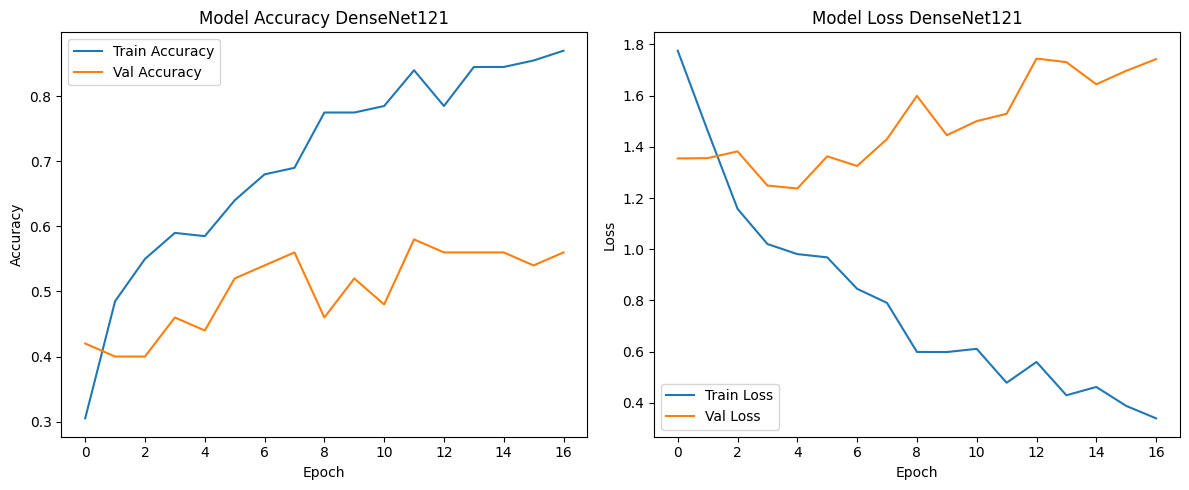

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_faster_rcnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_faster_rcnn.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy Faster R-CNN')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_faster_rcnn.history['loss'],     label='Train Loss')
plt.plot(history_faster_rcnn.history['val_loss'], label='Val Loss')
plt.title('Model Loss Faster R-CNN')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [ ]:
test_loss_faster_rcnn, test_acc_faster_rcnn = faster_rcnn_model.evaluate(test_dataset, verbose=0)
print(f'Test Loss: {test_loss_faster_rcnn:.4f}')
print(f'Test Accuracy: {test_acc_faster_rcnn:.4f}') 

Test Loss: 1.0166
Test Accuracy: 0.6230
